# Designing a physics-informed network (PINN) for chlorophyll under clouds

**Scope.** No PINN is trained here. This notebook lays out what a *properly trained* PINN for gap-filling surface chlorophyll (CHL) in the western Indian Ocean would look like, checks the relevant physics against the data in `IO.zarr`, and lists the pitfalls the literature warns about. Literature references with verification status are in [pinn_literature_notes.md](pinn_literature_notes.md); figures are in `figures/` (own drawings from `chl_cnn/schematics.py`, plus openly licensed schematics with credits).

**Data at hand** (0.25°, daily, 1997-09 to 2020-12, lat 32°N-5°S, lon 45-90°E): CHL L3 (cloud gaps), SST, salinity, 2 m air temperature, 10 m winds, SLA/ADT, mixed-layer depth, total and geostrophic surface currents, bathymetry.

**Setting.** The CNN/U-Net runs in [cnn_results.ipynb](cnn_results.ipynb) learn a map from (features, cloudy CHL) to CHL and are scored on hidden pixels. A PINN adds a second loss: the residual of a transport equation for CHL, evaluated on the network's *gap-free* output. This constrains the field under real clouds, where no data loss can act.


## 0. Introduction: the maths and physics you need for this notebook

Written for a reader with Calc II/III, differential equations and linear algebra, but no fluid dynamics. Everything below is used later; skip what you know.

### 0.1 Fields and the operators that act on them
The data are *fields* on a latitude-longitude grid: a **scalar field** $C(x,y,t)$ (chlorophyll, temperature) has one number per point, a **vector field** $\mathbf u(x,y,t)=(u,v)$ (a current, a wind) has an arrow per point. Four operators built from partial derivatives describe how fields vary in space:

| operator | formula (2-D) | meaning |
|---|---|---|
| gradient | $\nabla C = (\partial_x C,\ \partial_y C)$ | vector pointing uphill in $C$, length = steepness |
| divergence | $\nabla\cdot\mathbf u = \partial_x u + \partial_y v$ | net outflow per unit area (> 0: source, < 0: sink) |
| curl (vertical component) | $(\nabla\times\mathbf u)_z = \partial_x v - \partial_y u$ | local spin (> 0: counter-clockwise) |
| Laplacian | $\nabla^2 C = \partial_{xx} C + \partial_{yy} C$ | curvature: < 0 at a peak, > 0 in a trough; $\nabla^2 C = \nabla\cdot(\nabla C)$ |

![ops](figures/intro_vector_calculus.png)

On the grid every derivative becomes a difference of neighbouring pixels (stencil figure in Section 1.1): $\partial_x C \approx (C_{i+1}-C_{i-1})/(2\Delta x)$ and $\nabla^2 C \approx (C_{i+1}-2C_i+C_{i-1})/\Delta x^2 + (\ldots)_y$. Convolutional networks compute exactly such local differences, which is why a PDE residual can be written as a fixed convolution.

### 0.2 Following a parcel: the material derivative
$C$ can change at a fixed point for two reasons: the water there changes ($\partial_t C$), or different water is carried past by the current. The rate of change *following a parcel* is the material derivative
$$\frac{DC}{Dt} = \partial_t C + \mathbf u\cdot\nabla C = \partial_t C + u\,\partial_x C + v\,\partial_y C .$$
$\mathbf u\cdot\nabla C$ is the **advection** term: the dot product of the current with the gradient, i.e. how fast the current carries you up or down the $C$ hill. If nothing else happens, $DC/Dt=0$: a blob of tracer keeps its shape and just moves with the flow.

### 0.3 Advection, diffusion, sources: the tracer equation
Turbulent stirring below the grid scale smooths $C$ like heat conduction; it is modelled as **diffusion** with an eddy diffusivity $K$ (m² s⁻¹): $\partial_t C = K\nabla^2 C$ flattens peaks and fills troughs, so a blob spreads without moving. Anything that creates or destroys tracer is a **source/sink** $S$. Together:
$$\partial_t C + \mathbf u\cdot\nabla C = K\nabla^2 C + S .$$
This is the advection-diffusion-reaction equation, the only physical law the PINN in this notebook would enforce. For chlorophyll, $S$ contains phytoplankton growth and loss (biology) and vertical exchange (upwelling), which is where the wind enters.

![adv-diff](figures/intro_advection_diffusion.png)

Because $\ln C$ obeys the same advection form ($D\ln C/Dt = (1/C)\,DC/Dt$), the transport part can be written for $\ln$ CHL directly, which is the quantity the CNNs predict.

### 0.4 Grids, time steps and two dimensionless numbers
A daily 0.25° grid can only *represent* motion that is slow enough and smooth enough. Two ratios say what is resolvable:

* **Courant number** $\mathrm{Co} = u\,\Delta t/\Delta x$: how many cells a parcel crosses in one time step. Explicit finite-difference schemes are stable and accurate only for $\mathrm{Co}\lesssim 1$ (the CFL condition); at $\mathrm{Co}>1$ the parcel jumps over cells and a local stencil cannot follow it.
* **Péclet number** $\mathrm{Pe} = u\,\Delta x/K$: advection over diffusion across one cell. $\mathrm{Pe}\gg 1$ means fronts are carried, not smoothed; such problems are "hyperbolic" and are the ones the PINN literature reports as hardest to train.

![co-pe](figures/intro_courant_peclet.png)

### 0.5 Rotation, Coriolis and the Ekman layer
On the rotating Earth a moving parcel of water is deflected: to the right in the Northern Hemisphere, to the left in the Southern. The strength is the **Coriolis parameter** $f = 2\Omega\sin(\text{lat})$ ($\Omega$ = Earth's rotation rate), zero at the equator. Wind drags the surface; Coriolis turns the moving layer; friction passes momentum downward. The depth-integrated result, the **Ekman transport**, is at right angles to the wind, $M_E = \tau/(\rho f)$, where $\tau$ is the wind stress (force per area, proportional to wind speed squared). Where the transport diverges (a coast on its upstream side, or a wind field with positive curl), water must rise from below: **upwelling**, $w_E = \nabla\times(\boldsymbol\tau/\rho f)$. Because of the $1/f$, none of this is defined near the equator.

![coriolis](figures/intro_coriolis_ekman.png)

### 0.6 What a PINN does with all this
A neural network $C_\theta(x,y,t)$ is trained with two losses: a **data loss** (its output should match observed pixels, here the fake-cloud pixels as in the CNN runs) and a **physics loss** (its output should make the residual $r = \partial_t C_\theta + \mathbf u\cdot\nabla C_\theta - K\nabla^2 C_\theta - S$ small everywhere, including under clouds where there is no observation). The derivatives in $r$ are taken by finite differences on the grid. The physics loss acts as a regulariser that says "what is under the cloud must be consistent with what the current carried there yesterday". Whether that is a strong or a weak statement at 0.25° / daily resolution is what Section 2 tests.


## 1. Physics: what constrains surface chlorophyll

### 1.1 Tracer budget
Treat CHL (or ln CHL) in the mixed layer as a tracer $C(x,y,t)$ advected by the surface current $\mathbf{u}=(u,v)$:

$$\partial_t C + u\,\partial_x C + v\,\partial_y C \;=\; \nabla\cdot(K_h \nabla C) \;+\; S_w \;+\; R(C)$$

* **advection** by `u_curr`, `v_curr` (total surface currents, includes Ekman + geostrophic): the only term that is fully specified by the data.
* **horizontal eddy diffusion** $K_h$: at 25-40 km scale $K_h \sim 10^2$-$10^3$ m² s⁻¹ (Groeskamp et al. 2021; Okubo 1971). Diffusion length in a day is 3-9 km, well below the 27 km grid, so this term is a regulariser, not a constraint.
* **vertical exchange** $S_w = \max(w_E + \partial_t h, 0)\,(C_{sub}-C)/h$: upwelling ($w_E$) and mixed-layer deepening ($h$ = `mlotst`) bring subsurface water up. Directly it *dilutes* surface CHL (subsurface CHL is low outside the deep-chlorophyll maximum); indirectly it supplies nutrients that raise growth $R$ days to weeks later.
* **biology** $R(C)$: growth (light, nutrients, SST) minus grazing/sinking. Not specified by the data. Every physics-constrained CHL paper found (PPIDM, PeRCNN-style, Neural-BGC) *learns* this term and trusts only transport.

Because advection is a material derivative, the equation for $\ln C$ has the same advective form; only the sources change ($S/C$). We work in $\ln C$, like the CNNs.

![tracer](figures/pinn_tracer_equation.png)

### 1.2 Upwelling from wind
Wind stress from 10 m winds (bulk formula, Large & Pond 1981 drag): $\boldsymbol\tau = \rho_{air} C_D |\mathbf U_{10}| \mathbf U_{10}$.

* **Ekman transport** (volume, m² s⁻¹): $M_x = \tau_y/(\rho_w f)$, $M_y = -\tau_x/(\rho_w f)$: 90° to the right of the wind in the Northern Hemisphere. Along a coast with the coast on the right of the wind (Somalia, Oman, Yemen during the SW monsoon) the transport is offshore and the coast upwells. The Bakun index is the offshore component of $M$ per 100 m of coastline.
* **Ekman pumping** (open ocean): $w_E = \dfrac{1}{\rho_w}\nabla\times\left(\dfrac{\boldsymbol\tau}{f}\right) = \dfrac{\partial_x\tau_y - \partial_y\tau_x}{\rho_w f} + \dfrac{\beta\,\tau_x}{\rho_w f^2}$, positive upward. During the SW monsoon the Findlater jet has positive curl (upwelling) inshore of its axis and negative curl offshore (Beal et al. 2013).
* **Magnitudes (literature):** Somali section $w_E$ > 4 m day⁻¹ at peak monsoon (Chatterjee et al. 2019); off Yemen > 1 m day⁻¹ (JJAS); SE Arabian Sea 0.5-1.5 m day⁻¹. Surface currents 0.2-0.5 m s⁻¹ in the interior, 1.5-3 m s⁻¹ in the Somali Current / Great Whirl.
* **Caveat 1, equator:** $M \propto 1/f$, $w_E \propto 1/f^2$. The domain reaches 5°S; within roughly ±3° the Ekman terms are meaningless and must be masked or tapered.
* **Caveat 2, not monotone:** Chatterjee et al. (2019) show Somali upwelling shuts down in August despite favourable winds (thermocline deepens from 20 to 80 m). Wind → upwelling → CHL is not a fixed mapping; the mixed-layer depth and the lag matter.
* **Caveat 3, lags:** CHL responds to upwelling with lags from 3-4 days (events) to 1-2 months (basin scale; Yao & Hoteit 2015; Wang et al. 2021). A daily PDE residual with instantaneous forcing cannot express this; the source term needs a lagged/integrated forcing or an explicit nutrient state.

![upwelling](figures/pinn_upwelling.png)

Openly licensed schematics (kept for reference; the Wikimedia drawing is for the Southern Hemisphere, where transport is to the *left* of the wind):

<table><tr>
<td><img src="figures/upwelling_noaa.jpg" width="420"><br><small>NOAA National Ocean Service, "What is upwelling?" (US Government work)</small></td>
<td><img src="figures/ekman_spiral_ccbysa.jpg" width="330"><br><small>Ekman spiral and transport under zonal wind stress, Dutchoceanographer, Wikimedia Commons, CC BY-SA 4.0</small></td>
</tr></table>


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys

sys.path.insert(0, "..")
from chl_cnn import store as S, physics as P, data as D
from chl_cnn.plotting import OKABE_ITO as OI

d = S.load_store()
times = pd.to_datetime(d["time"])
lat, lon, ocean = d["lat"], d["lon"], d["ocean"]
yr = times.year.values
mo = times.month.values


def days(y, m=None):
    return np.flatnonzero((yr == y) & ((mo == m) if m is not None else True))


def month_mean(var, idx):
    return np.asarray(d[var][idx]).astype("float32").mean(0)


print(len(times), "days;", ocean.sum(), "ocean pixels")

8461 days; 16695 ocean pixels


## 2. Sanity checks against the data

Before designing a loss around these terms, check that they have the expected size on this grid. Assumptions: 2019 is used as a representative year (the year with most clear days); Ekman quantities are masked for |lat| < 3°; wind stress uses the Large & Pond drag.

### 2.1 Ekman pumping from the 10 m winds, SW vs NE monsoon

July 2019 (SW monsoon): w_E m/day  p1 -1.59  p50 0.00  p99 4.91   (n ocean px 12549)
January 2019 (NE monsoon): w_E m/day  p1 -2.93  p50 -0.12  p99 1.47   (n ocean px 12549)


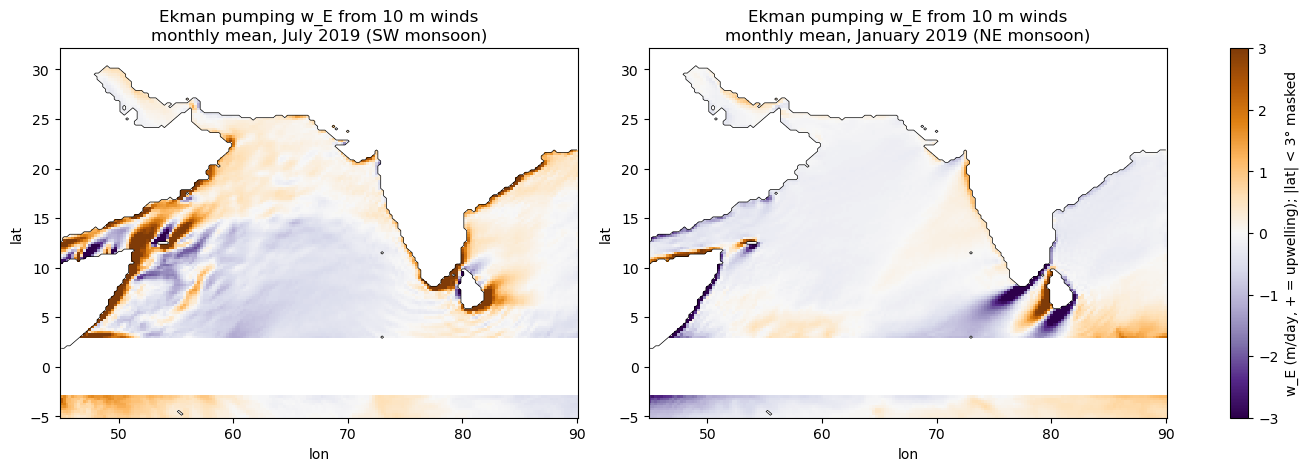

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
for ax, m, name in zip(
    axes, [7, 1], ["July 2019 (SW monsoon)", "January 2019 (NE monsoon)"]
):
    idx = days(2019, m)
    uw, vw = np.asarray(d["u_wind"][idx]).astype("float32"), np.asarray(
        d["v_wind"][idx]
    ).astype("float32")
    w = (
        np.stack([P.ekman(uw[i], vw[i], lat, lon)[2] for i in range(len(idx))]).mean(0)
        * 86400
    )  # m/day
    w[~ocean] = np.nan
    im = ax.pcolormesh(lon, lat, w, cmap="PuOr_r", vmin=-3, vmax=3, shading="auto")
    ax.contour(lon, lat, ocean.astype(float), levels=[0.5], colors="k", linewidths=0.5)
    ax.set_title(f"Ekman pumping w_E from 10 m winds\nmonthly mean, {name}")
    ax.set_xlabel("lon")
    ax.set_ylabel("lat")
    q = np.nanpercentile(w[ocean], [1, 50, 99])
    print(
        f"{name}: w_E m/day  p1 {q[0]:.2f}  p50 {q[1]:.2f}  p99 {q[2]:.2f}   (n ocean px {np.isfinite(w[ocean]).sum()})"
    )
fig.colorbar(im, ax=axes, label="w_E (m/day, + = upwelling); |lat| < 3° masked")

### 2.2 Are the currents resolvable at daily / 0.25°? (Courant number)

July 2019 daily Courant number: median 1.05, fraction > 1: 0.52, > 2: 0.17   (n = 511438)
January 2019: median 0.96, fraction > 1: 0.48   (n = 511438)


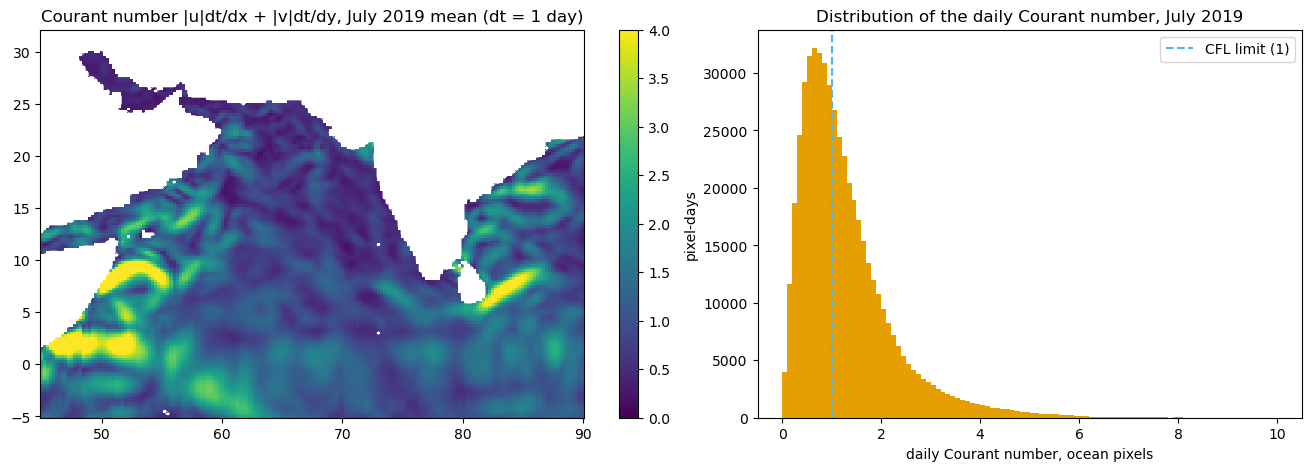

In [ ]:
idx = days(2019, 7)
uc, vc = np.asarray(d["u_curr"][idx]).astype("float32"), np.asarray(
    d["v_curr"][idx]
).astype("float32")
cr = np.stack(
    [P.courant(uc[i], vc[i], lat, lon) for i in range(len(idx))]
)  # daily Courant number
cr_mean = np.nanmean(cr, 0)
cr_mean[~ocean] = np.nan
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
im = axes[0].pcolormesh(
    lon, lat, cr_mean, cmap="viridis", vmin=0, vmax=4, shading="auto"
)
axes[0].contour(lon, lat, ocean.astype(float), levels=[0.5], colors="w", linewidths=0.5)
axes[0].set_title("Courant number |u|dt/dx + |v|dt/dy, July 2019 mean (dt = 1 day)")
fig.colorbar(im, ax=axes[0])
v = cr[:, ocean]
v = v[np.isfinite(v)]
axes[1].hist(v, bins=np.linspace(0, 10, 101), color=OI[1])
axes[1].axvline(1, color=OI[5], ls="--", label="CFL limit (1)")
axes[1].set_xlabel("daily Courant number, ocean pixels")
axes[1].set_ylabel("pixel-days")
axes[1].legend()
axes[1].set_title("Distribution of the daily Courant number, July 2019")
print(
    f"July 2019 daily Courant number: median {np.median(v):.2f}, fraction > 1: {(v > 1).mean():.2f}, > 2: {(v > 2).mean():.2f}   (n = {v.size})"
)
idx = days(2019, 1)
uc, vc = np.asarray(d["u_curr"][idx]).astype("float32"), np.asarray(
    d["v_curr"][idx]
).astype("float32")
v = np.stack([P.courant(uc[i], vc[i], lat, lon) for i in range(len(idx))])[:, ocean]
v = v[np.isfinite(v)]
print(
    f"January 2019: median {np.median(v):.2f}, fraction > 1: {(v > 1).mean():.2f}   (n = {v.size})"
)

### 2.3 How much of the day-to-day change in ln CHL does advection explain?

For consecutive days in 2019 and pixels where ln CHL is observed on both days *and* at the four neighbours (centred differences), compare the tendency $\partial_t C$ with $-\mathbf u\cdot\nabla C$. If the transport equation held with small sources, the two would correlate strongly. Note the selection bias: pixels observed on two consecutive days are the less cloudy ones.

353 consecutive-day pairs in 2019, median 3364 usable pixels per pair
      r_tend_adv  sd tendency (ln/day)  sd u.grad C (ln/day)  \
mean       0.114                 0.219                 0.148   
50%        0.110                 0.215                 0.124   
min       -0.171                 0.119                 0.063   
max        0.351                 0.424                 0.479   

      sd K lap C, K=500 (ln/day)  
mean                       0.035  
50%                        0.034  
min                        0.017  
max                        0.066  


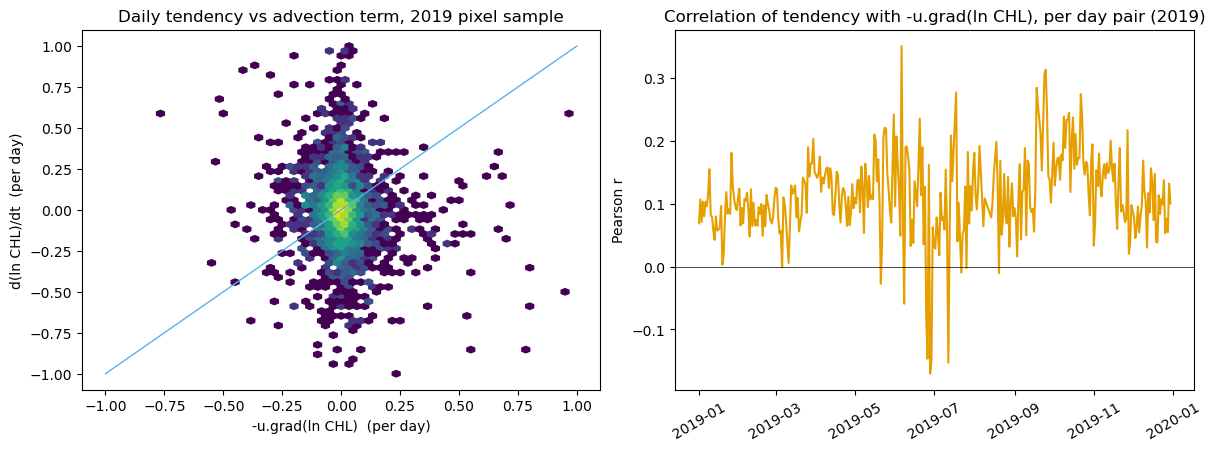

In [ ]:
y = D.log_chl(np.asarray(d["chl_l3"][days(2019)]))
t19 = times[days(2019)]
u19, v19 = d["u_curr"][days(2019)], d["v_curr"][days(2019)]
rows, samples = [], []
for i in range(len(t19) - 1):
    if (t19[i + 1] - t19[i]).days != 1:
        continue
    c0, c1 = y[i], y[i + 1]
    tend, adv, lap = P.tracer_terms(
        c0,
        c1,
        np.asarray(u19[i]).astype("float32"),
        np.asarray(v19[i]).astype("float32"),
        lat,
        lon,
    )
    m = np.isfinite(tend) & np.isfinite(adv) & np.isfinite(lap) & ocean
    if m.sum() < 500:
        continue
    rows.append(
        dict(
            date=t19[i],
            n=int(m.sum()),
            r_tend_adv=np.corrcoef(tend[m], -adv[m])[0, 1],
            sd_tend=tend[m].std() * 86400,
            sd_adv=adv[m].std() * 86400,
            sd_lap_K500=(500 * lap[m]).std() * 86400,
        )
    )
    if len(samples) < 40:
        samples.append(np.c_[tend[m], -adv[m], lap[m]][::50])
df = pd.DataFrame(rows)
s = np.concatenate(samples)
print(
    f"{len(df)} consecutive-day pairs in 2019, median {int(df.n.median())} usable pixels per pair"
)
print(
    df[["r_tend_adv", "sd_tend", "sd_adv", "sd_lap_K500"]]
    .describe()
    .loc[["mean", "50%", "min", "max"]]
    .round(3)
    .rename(
        columns={
            "sd_tend": "sd tendency (ln/day)",
            "sd_adv": "sd u.grad C (ln/day)",
            "sd_lap_K500": "sd K lap C, K=500 (ln/day)",
        }
    )
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
axes[0].hexbin(
    -s[:, 1] * 86400,
    s[:, 0] * 86400,
    gridsize=60,
    extent=(-1, 1, -1, 1),
    cmap="viridis",
    bins="log",
)
axes[0].plot([-1, 1], [-1, 1], color=OI[5], lw=1)
axes[0].set_xlabel("-u.grad(ln CHL)  (per day)")
axes[0].set_ylabel("d(ln CHL)/dt  (per day)")
axes[0].set_title("Daily tendency vs advection term, 2019 pixel sample")
axes[1].plot(df.date, df.r_tend_adv, color=OI[1])
axes[1].axhline(0, color="k", lw=0.5)
axes[1].set_ylabel("Pearson r")
axes[1].set_title("Correlation of tendency with -u.grad(ln CHL), per day pair (2019)")
axes[1].tick_params(axis="x", rotation=30)

### 2.4 Does upwelling forcing lead CHL at the coast, and by how much?

Monthly means over 1998-2020 in two coastal boxes (Somali coast 5-12°N, 48-53°E; Oman coast 17-22°N, 56-60°E). Forcing = monthly mean offshore Ekman transport magnitude $|M|$ from the winds (box mean). Cross-correlation of the monthly anomalies (seasonal cycle kept) of ln CHL with the forcing at lags 0-4 months.

Somali coast (5-12N, 48-53E)  r by lag 0-4 months: [ 0.67  0.67  0.36  0.06 -0.12]  n months 276  median CHL obs per month 4086
Oman coast (17-22N, 56-60E)  r by lag 0-4 months: [ 0.6   0.78  0.58  0.15 -0.19]  n months 271  median CHL obs per month 2774


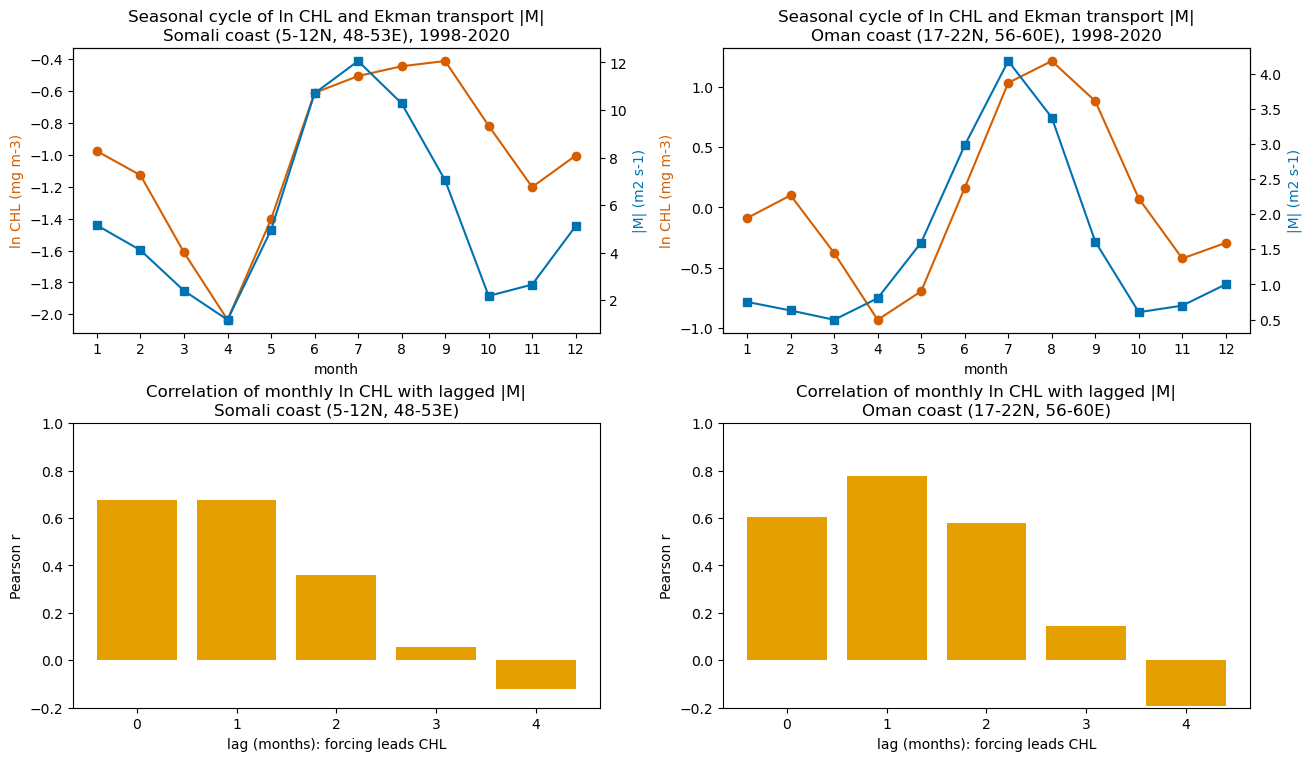

In [ ]:
boxes = {
    "Somali coast (5-12N, 48-53E)": (5, 12, 48, 53),
    "Oman coast (17-22N, 56-60E)": (17, 22, 56, 60),
}


def box_sl(la0, la1, lo0, lo1):
    i = np.flatnonzero((lat >= la0) & (lat <= la1))
    j = np.flatnonzero((lon >= lo0) & (lon <= lo1))
    return slice(i.min(), i.max() + 1), slice(j.min(), j.max() + 1)


fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), constrained_layout=True)
for k, (name, b) in enumerate(boxes.items()):
    ii, jj = box_sl(*b)
    oc = ocean[ii, jj]
    uw = np.asarray(d["u_wind"][:, ii, jj]).astype("float32")
    vw = np.asarray(d["v_wind"][:, ii, jj]).astype("float32")
    tx, ty = P.wind_stress(uw, vw)
    f = 2 * P.OMEGA * np.sin(np.deg2rad(lat[ii]))[None, :, None]
    M = np.hypot(ty, tx) / (P.RHO_W * f)  # Ekman transport magnitude, m2/s
    chl = D.log_chl(np.asarray(d["chl_l3"][:, ii, jj]))
    s = pd.DataFrame(
        {
            "M": np.nanmean(np.where(oc, M, np.nan).reshape(len(times), -1), 1),
            "chl": np.nanmean(np.where(oc, chl, np.nan).reshape(len(times), -1), 1),
            "nobs": np.isfinite(np.where(oc, chl, np.nan).reshape(len(times), -1)).sum(
                1
            ),
        },
        index=times,
    )
    mth = s.resample("MS").mean()
    mth["nobs"] = s["nobs"].resample("MS").sum()
    mth = mth[(mth.index.year >= 1998)]
    clim = mth.groupby(mth.index.month).mean()
    ax = axes[0, k]
    ax.plot(clim.index, clim["chl"], color=OI[3], marker="o", label="ln CHL (box mean)")
    ax.set_ylabel("ln CHL (mg m-3)", color=OI[3])
    ax2 = ax.twinx()
    ax2.plot(clim.index, clim["M"], color=OI[0], marker="s", label="|Ekman transport|")
    ax2.set_ylabel("|M| (m2 s-1)", color=OI[0])
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("month")
    ax.set_title(f"Seasonal cycle of ln CHL and Ekman transport |M|\n{name}, 1998-2020")
    lags = range(0, 5)
    r = [mth["chl"].corr(mth["M"].shift(l)) for l in lags]
    nn = [int(mth[["chl", "M"]].shift(l).dropna().shape[0]) for l in lags]
    ax = axes[1, k]
    ax.bar(list(lags), r, color=OI[1])
    ax.set_xlabel("lag (months): forcing leads CHL")
    ax.set_ylabel("Pearson r")
    ax.set_ylim(-0.2, 1)
    ax.set_title(f"Correlation of monthly ln CHL with lagged |M|\n{name}")
    print(
        name,
        " r by lag 0-4 months:",
        np.round(r, 2),
        " n months",
        nn[0],
        " median CHL obs per month",
        int(mth.nobs.median()),
    )

### 2.5 What the checks show (observations)

| check | result | literature expectation |
|---|---|---|
| Ekman pumping, July 2019 monthly mean | p99 = 4.9 m/day, upwelling along the Somali, Omani and Indian west coasts; downwelling offshore of the jet axis | > 4 m/day Somali section (Chatterjee et al. 2019); positive curl inshore, negative offshore (Beal et al. 2013) |
| Ekman pumping, January 2019 | p1 = -2.9, p99 = 1.5 m/day; strong downwelling south of Sri Lanka | weaker, reversed NE-monsoon forcing |
| Courant number, July 2019, 511 k pixel-days | median 1.05, 52 % > 1, 17 % > 2; January median 0.96 | u dt/dx > 1 for u > 0.3 m/s |
| daily tendency vs advection, 2019, 353 day pairs, median 3.4 k px/pair | r = 0.11 (median), sd tendency 0.22 ln/day, sd advection 0.12 ln/day, sd K lap C (K = 500) 0.03 ln/day | advection should be a leading term if the tracer equation held at this resolution |
| monthly ln CHL vs Ekman transport, 1998-2020 | Somali coast: r = 0.67 at lags 0 and 1 month; Oman coast: r = 0.78 at lag 1 month, 0.60 at lag 0 (n = 271-276 months) | 1-2 month lag (Yao & Hoteit 2015; Wang et al. 2021) |

The tendency/advection scatter (2.3) is the most consequential: on observed pixels the day-to-day change in ln CHL is dominated by something other than resolved advection (sensor noise between days, sub-grid processes, biology, and the selection to twice-observed pixels). Diffusion at a defensible K is an order of magnitude smaller still. Open question for the supervisor: is a residual with r ~ 0.1 against the data a usable constraint at all, or does the physics have to enter as structure (features, lags, sign constraints) rather than as a PDE penalty?

## 3. Prior work that matters for this design

| approach | what it does | relevance |
|---|---|---|
| DINEOF / DINCAE (Beckers & Rixen 2003; Barth et al. 2020; Han et al. 2020 for CHL) | EOF or convolutional autoencoder gap filling, no physics | the standard baselines; DINCAE is what our CNN/U-Net approximates |
| OCNET (Hong et al. 2023) | U-Net CHL gap filling 0.25° daily from SST, salinity, PAR, climatology | closest data-driven twin of our setup; CC 0.6-0.7 |
| 4DVarNet (Fablet et al. 2023; Nguyen et al. 2025 for ocean colour) | learned variational assimilation: a learned prior + a learned solver | the prior could be the advection-diffusion operator; > 20 % gain over OI/DINEOF on CHL |
| PPIDM (Xu & Li, NeurIPS 2025) | diffusion model for CHL with a *partial* physics loss: only the advection operator is enforced, biology is left free | closest statement of the "trust transport, learn biology" split |
| PeRCNN (Rao et al. 2023), PhyCRNet (Ren et al. 2022), PhyGeoNet (Gao et al. 2021), Zhu et al. 2019 | PDE residuals computed with finite-difference/convolution stencils on grids, known terms hard-wired, unknown term learned | the right mechanics for gridded daily data (no autodiff in x, y) |
| Hidden fluid mechanics (Raissi et al. 2020) | infers velocities from passive-scalar transport | inverse of our problem; shows the tracer equation is learnable |
| SSTODE (2025), PDE-guided SST nets (2023) | neural ODE / PDE-guided nets with explicit advection-diffusion for SST | same transport operator, different tracer |
| Neural-BGC (Ouala et al. 2026), neural closures (Gupta & Lermusiaux) | NN replaces the biogeochemical source term inside a physical model | template for $R(C)$ |

No paper was found that uses Ekman pumping or wind-stress curl as a PDE residual term for CHL; upwelling indices appear only as *features*.

## 4. Pitfalls documented for PINN training, and what they mean here

| pitfall | source | consequence for this problem |
|---|---|---|
| PINNs fail on convection-dominated problems already at moderate speeds; the soft PDE penalty ill-conditions the loss | Krishnapriyan et al. 2021; Mojgani et al. 2023 | our grid Péclet number is 10-100 and the Courant number is > 1 in the boundary currents: this *is* the hard case |
| gradient imbalance between data and PDE terms | Wang, Teng & Perdikaris 2021; Wang, Yu & Perdikaris 2022 (NTK) | $\lambda_{pde}$ must be adaptive (grad-norm or NTK weighting), not a fixed constant |
| spectral bias: smooth solutions learned first, fronts last | Rahaman et al. 2019; Wang et al. 2021 | coastal CHL fronts on a smooth background; Fourier features or a multi-scale (U-Net) backbone |
| violating causality when fitting all times at once | Wang, Sankaran & Perdikaris 2022 | train on short windows (t-k..t+k) and weight residuals causally |
| hard vs soft constraints | Lu et al. 2021 | observed pixels can be *hard* constraints (paste them back), physics stays soft |
| finite-difference residuals on coarse grids are noisy | PhyCRNet, PeRCNN | use upwind/flux-limited advection, mask the stencil at land, and never evaluate residuals across the equatorial band for Ekman terms |

## 5. What a proper PINN for this task would be

![architecture](figures/pinn_architecture.png)

**Backbone.** Keep the best data-driven model (U-Net or dilated CNN from `cnn_results.ipynb`) and give it a window of days $t-k..t+k$ so it outputs a *gap-free* sequence $\hat C_{t-1}, \hat C_t, \hat C_{t+1}$. Observed pixels are pasted back (hard constraint). Inputs as in the CNN runs plus precomputed $\tau$, $M$, $w_E$ (masked for |lat| < 3°).

**Losses.**
1. Data: hidden-pixel loss on fake clouds, exactly as now (pixels under real clouds never enter it).
2. Transport residual on the network output, everywhere on the ocean grid including under real clouds:
   $r = \dfrac{\hat C_{t+1} - \hat C_{t-1}}{2\Delta t} + \mathbf u\cdot\nabla \hat C_t - K_h\nabla^2\hat C_t - S_\phi$ with an **upwind or semi-Lagrangian** advection stencil (Section 2.2 shows the Courant number exceeds 1 over a large fraction of pixel-days, so a centred explicit stencil would be unstable as a constraint). $K_h$ is a learned scalar bounded to $10^2$-$10^3$ m² s⁻¹.
3. Source term $S_\phi$: a small learned network of (lagged) $w_E^+$, Ekman transport, MLD tendency, SST and $\hat C$ itself, i.e. the PPIDM/PeRCNN split. Physics enters as *structure* (what $S$ may depend on, sign of the upwelling effect via a positivity constraint on the nutrient pathway, lags of 0-30 days as a learned kernel), not as a hard-coded formula, because Section 1.2 and the sanity checks show the wind-to-CHL link is lagged and not monotone.
4. Loss balancing: gradient-norm or NTK weights (Wang et al. 2021/2022), annealed so the transport term is weak at the start (curriculum, Krishnapriyan et al. 2021).

**Evaluation.** Same fixed fake-cloud pixels as the CNN runs, plus a physics-only check: residual size under real clouds vs under observed pixels. A PINN should be preferred only if it beats the best purely data-driven model on the hidden-pixel MAE *and* lowers the residual under real clouds.

**Cost.** The residual needs three consecutive output fields per sample, so roughly 3x the forward cost of the U-Net per step. On the T4 that is ~1-2 h per 30-epoch run.

## 6. Open questions before training anything
* Which advection stencil to use at Courant > 1 (semi-Lagrangian back-trajectories vs sub-cycling the daily currents)?
* Is the source term trained jointly or pre-fitted on clear days (Section 2.4 gives the lag structure it must reproduce)?
* How to treat the equatorial band: drop the Ekman channels there, or replace them by the divergence of the total currents?
* What loss weight range keeps the model from collapsing to a smooth, physics-satisfying but data-poor field (a known PINN failure)?
